In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/batooljuaitem/titanic/gender_submission.csv
/kaggle/input/datasets/batooljuaitem/titanic/test.csv
/kaggle/input/datasets/batooljuaitem/titanic/train.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/batooljuaitem/titanic/gender_submission.csv
/kaggle/input/datasets/batooljuaitem/titanic/test.csv
/kaggle/input/datasets/batooljuaitem/titanic/train.csv


In [4]:
# Load Titanic training dataset

df = pd.read_csv('/kaggle/input/datasets/batooljuaitem/titanic/train.csv')

# Display first 5 rows

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
# Dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
# Check missing values in each column

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [8]:
# Check data types of each column

print(df.dtypes)

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [9]:
# Drop unnecessary columns

df = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

# Display remaining columns

print("Remaining Columns:")
print(df.columns)

Remaining Columns:
Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked'],
      dtype='object')


In [10]:
# Handle missing values

df['Age'] = df['Age'].fillna(df['Age'].median())

df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Check missing values again

print("Missing Values After Handling:")
print(df.isnull().sum())

Missing Values After Handling:
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [11]:
# Convert categorical columns into numerical values

df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

df = pd.get_dummies(df, columns=['Embarked'], dtype=int)

# Display the updated dataset

df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,1,38.0,1,0,71.2833,1,0,0
2,1,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,0,1


In [12]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

Columns:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S']

Dataset Shape:
(891, 10)

First 5 Rows:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,1,38.0,1,0,71.2833,1,0,0
2,1,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,0,1


In [13]:
# Separate Features and Target

X = df.drop('Survived', axis=1).values
y = df['Survived'].values

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (891, 9)
Target Shape: (891,)


In [14]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Shape: (712, 9)
Testing Shape: (179, 9)
Training Target Shape: (712,)
Testing Target Shape: (179,)


In [15]:
# Apply Standardization

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print("Training Mean:", np.mean(X_train, axis=0))
print("Training Standard Deviation:", np.std(X_train, axis=0))

Training Mean: [-1.48445550e-16  2.78803198e-16  2.00779624e-16 -1.17259510e-16
 -8.57616100e-18  1.48576142e-15  1.50160783e-16  6.01266852e-16
  2.27969953e-16]
Training Standard Deviation: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [16]:
# Sigmoid Function

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [17]:
# Loss Function

def compute_loss(y_true, y_pred):
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

    return loss

In [18]:
# Stochastic Gradient Descent (SGD)

def train_sgd(X, y, learning_rate=0.01, epochs=1000):

    m, n = X.shape
    weights = np.zeros(n)
    bias = 0

    loss_history = []

    for epoch in range(epochs):

        indices = np.random.permutation(m)

        for i in indices:
            xi = X[i]
            yi = y[i]

            z = np.dot(xi, weights) + bias
            y_pred = sigmoid(z)

            dw = (y_pred - yi) * xi
            db = y_pred - yi

            weights -= learning_rate * dw
            bias -= learning_rate * db

        predictions = sigmoid(np.dot(X, weights) + bias)
        loss = compute_loss(y, predictions)
        loss_history.append(loss)

    return weights, bias, loss_history

In [19]:
weights, bias, loss_history = train_sgd(
    X_train,
    y_train,
    learning_rate=0.01,
    epochs=1000
)

print("SGD Training Completed!")
print("Final Loss:", loss_history[-1])

SGD Training Completed!
Final Loss: 0.4364806809644622


In [20]:
# Display Loss Progress

for i in range(0, len(loss_history), 100):
    print(f"Epoch {i+1}, Loss: {loss_history[i]:.4f}")

print(f"Epoch 1000, Loss: {loss_history[-1]:.4f}")

Epoch 1, Loss: 0.4583
Epoch 101, Loss: 0.4379
Epoch 201, Loss: 0.4382
Epoch 301, Loss: 0.4369
Epoch 401, Loss: 0.4368
Epoch 501, Loss: 0.4366
Epoch 601, Loss: 0.4373
Epoch 701, Loss: 0.4366
Epoch 801, Loss: 0.4368
Epoch 901, Loss: 0.4367
Epoch 1000, Loss: 0.4365


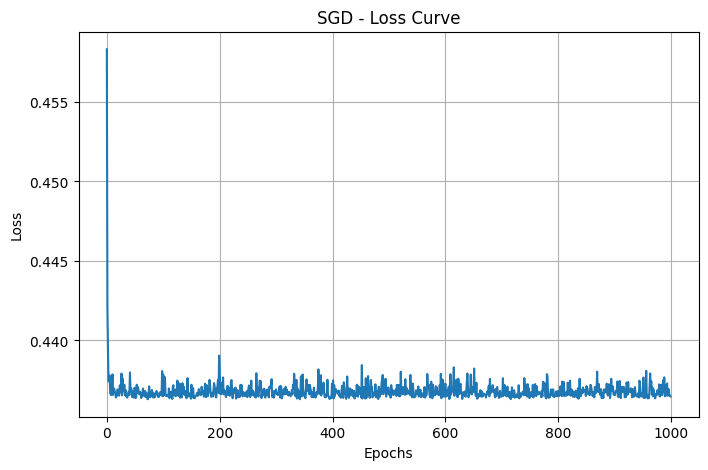

In [21]:
# Plot Loss Curve

plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.title("SGD - Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

In [22]:
# Make Predictions

y_prob = sigmoid(np.dot(X_test, weights) + bias)

y_pred = (y_prob >= 0.5).astype(int)

print("Predictions:", y_pred[:10])

Predictions: [0 0 0 0 1 0 1 0 0 0]


In [23]:
# Evaluate Model Performance

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("SGD Results:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

SGD Results:
Accuracy: 0.8100558659217877
Precision: 0.7966101694915254
Recall: 0.6811594202898551
F1 Score: 0.734375


In [24]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[98 12]
 [22 47]]


In [25]:
# Stochastic Gradient Descent with Momentum

def train_sgd_momentum(X, y, learning_rate=0.01, epochs=1000, beta=0.9):

    m, n = X.shape
    weights = np.zeros(n)
    bias = 0

    v_w = np.zeros(n)
    v_b = 0

    loss_history = []

    for epoch in range(epochs):

        indices = np.random.permutation(m)

        for i in indices:
            xi = X[i]
            yi = y[i]

            z = np.dot(xi, weights) + bias
            y_pred = sigmoid(z)

            dw = (y_pred - yi) * xi
            db = y_pred - yi

            v_w = beta * v_w + (1 - beta) * dw
            v_b = beta * v_b + (1 - beta) * db

            weights -= learning_rate * v_w
            bias -= learning_rate * v_b

        predictions = sigmoid(np.dot(X, weights) + bias)
        loss = compute_loss(y, predictions)
        loss_history.append(loss)

    return weights, bias, loss_history

In [26]:
# Train the Model using SGD with Momentum

weights_momentum, bias_momentum, loss_history_momentum = train_sgd_momentum(
    X_train,
    y_train,
    learning_rate=0.01,
    epochs=1000,
    beta=0.9
)

print("SGD with Momentum Training Completed!")

SGD with Momentum Training Completed!


In [27]:

# Display Loss Progress - SGD with Momentum

for i in range(0, len(loss_history_momentum), 100):
    print(f"Epoch {i+1}, Loss: {loss_history_momentum[i]:.4f}")

print("-" * 40)
print(f"Final Epoch: {len(loss_history_momentum)}")
print(f"Final Loss: {loss_history_momentum[-1]:.4f}")


Epoch 1, Loss: 0.4590
Epoch 101, Loss: 0.4366
Epoch 201, Loss: 0.4385
Epoch 301, Loss: 0.4367
Epoch 401, Loss: 0.4364
Epoch 501, Loss: 0.4365
Epoch 601, Loss: 0.4364
Epoch 701, Loss: 0.4365
Epoch 801, Loss: 0.4379
Epoch 901, Loss: 0.4368
----------------------------------------
Final Epoch: 1000
Final Loss: 0.4367


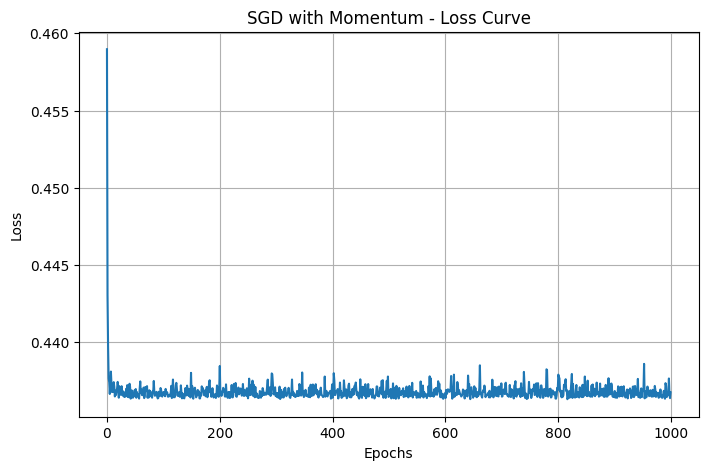

In [28]:
# Plot Loss Curve

plt.figure(figsize=(8, 5))
plt.plot(loss_history_momentum)
plt.title("SGD with Momentum - Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

In [29]:
# Make Predictions

y_prob_momentum = sigmoid(np.dot(X_test, weights_momentum) + bias_momentum)
y_pred_momentum = (y_prob_momentum >= 0.5).astype(int)

print("Predictions:", y_pred_momentum[:10])

Predictions: [0 0 0 0 1 0 1 0 0 0]


In [30]:
# Evaluate Model Performance

accuracy = accuracy_score(y_test, y_pred_momentum)
precision = precision_score(y_test, y_pred_momentum)
recall = recall_score(y_test, y_pred_momentum)
f1 = f1_score(y_test, y_pred_momentum)

print("SGD with Momentum Results:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

SGD with Momentum Results:
Accuracy: 0.8100558659217877
Precision: 0.7777777777777778
Recall: 0.7101449275362319
F1 Score: 0.7424242424242424


In [31]:
cm_momentum = confusion_matrix(y_test, y_pred_momentum)

print("Confusion Matrix:")
print(cm_momentum)

Confusion Matrix:
[[96 14]
 [20 49]]


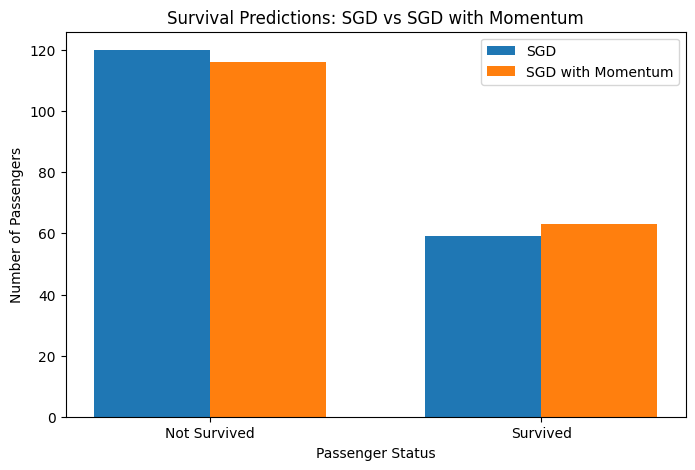

In [32]:
# Compare Survival Predictions: SGD vs SGD with Momentum

sgd_not_survived = np.sum(y_pred == 0)
sgd_survived = np.sum(y_pred == 1)

momentum_not_survived = np.sum(y_pred_momentum == 0)
momentum_survived = np.sum(y_pred_momentum == 1)

labels = ['Not Survived', 'Survived']
sgd_counts = [sgd_not_survived, sgd_survived]
momentum_counts = [momentum_not_survived, momentum_survived]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, sgd_counts, width, label='SGD')
plt.bar(x + width/2, momentum_counts, width, label='SGD with Momentum')

plt.xlabel('Passenger Status')
plt.ylabel('Number of Passengers')
plt.title('Survival Predictions: SGD vs SGD with Momentum')
plt.xticks(x, labels)
plt.legend()
plt.show()

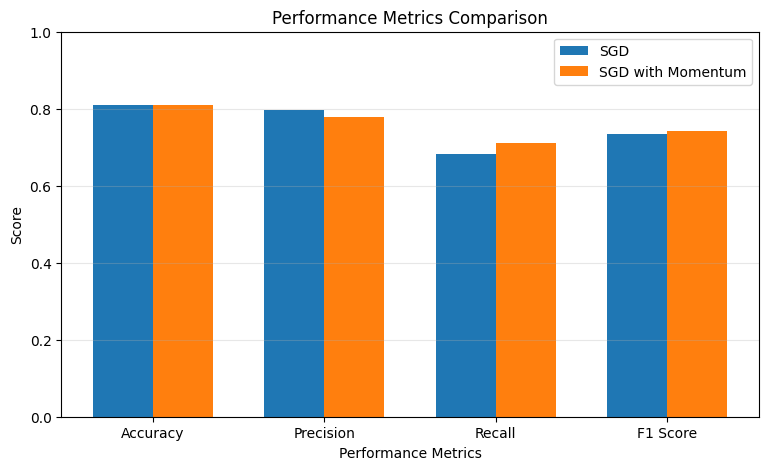

In [33]:
# Performance Metrics Comparison: SGD vs SGD with Momentum

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

sgd_scores = [
    accuracy_score(y_test, y_pred),
    precision_score(y_test, y_pred),
    recall_score(y_test, y_pred),
    f1_score(y_test, y_pred)
]

momentum_scores = [
    accuracy_score(y_test, y_pred_momentum),
    precision_score(y_test, y_pred_momentum),
    recall_score(y_test, y_pred_momentum),
    f1_score(y_test, y_pred_momentum)
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, sgd_scores, width, label='SGD')
plt.bar(x + width/2, momentum_scores, width, label='SGD with Momentum')

plt.xlabel('Performance Metrics')
plt.ylabel('Score')
plt.title('Performance Metrics Comparison')
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

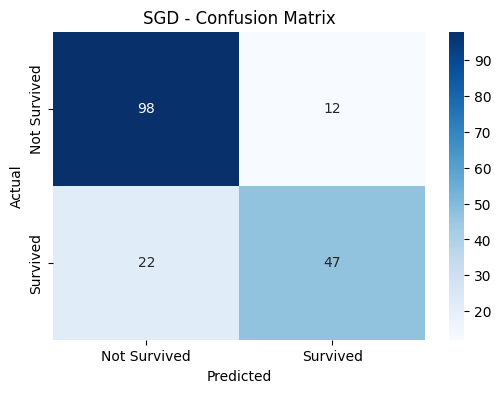

In [34]:
# Confusion Matrix - SGD

cm_sgd = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_sgd,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('SGD - Confusion Matrix')
plt.show()

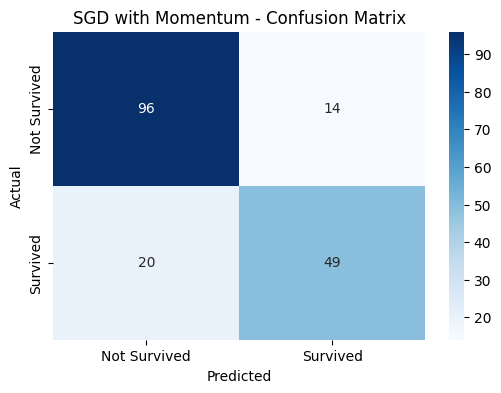

In [35]:
# Confusion Matrix - SGD with Momentum

cm_momentum = confusion_matrix(y_test, y_pred_momentum)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_momentum,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('SGD with Momentum - Confusion Matrix')
plt.show()